# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**

**Устройство.** Mac, GPU через MPS; Python 3.14, PyTorch 2.14.1, ultralytics 8.4.208. Финальные эксперименты выполнены с FAST_MODE = False.

**Данные.** [HIT-UAV v1.2.1](https://zenodo.org/records/7633134), лицензия CC0 1.0. Подготовка и фильтрация описаны в разделе 2.1.

**Источники.** Общие функции и открытые тесты из заготовки ДЗ2; документация ultralytics по [YOLO26](https://docs.ultralytics.com/models/yolo26/), [обучению](https://docs.ultralytics.com/modes/train/) и [валидации](https://docs.ultralytics.com/modes/val/).

**Дополнительные источники.** Документация по [экспорту ONNX](https://docs.ultralytics.com/modes/export/) и [числу потоков ONNX Runtime](https://onnxruntime.ai/docs/performance/tune-performance/threading.html).

**Готовность.** Обязательные задания 1–5 и бонусы 6.3, 6.4, 6.5 выполнены; бонусы 6.1 и 6.2 не выбраны. Разделы запускались отдельно; полный Restart & Run All после последних правок не выполнялся.


In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path
from IPython.display import display
from typing import Any

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.208, torch 2.14.1, device: mps


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.4', '6.5'}
BONUS_RESULTS = {}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
BENCHMARK_IMGSZ = 640
WARMUP_RUNS = 5
BENCHMARK_RUNS = 20


def synchronize_device() -> None:
    if isinstance(DEVICE, int) or str(DEVICE).startswith("cuda"):
        torch.cuda.synchronize(DEVICE)
    elif str(DEVICE) == "mps":
        torch.mps.synchronize()


def benchmark_model(weights: str) -> dict[str, str | int | float]:
    model = YOLO(weights)
    weights_path = (
        Path(weights)
        if Path(weights).exists()
        else Path(model.ckpt_path)
    )

    info = {
        "ultralytics": ultralytics.__version__,
        "weights": weights_path.name,
        "sha256": hashlib.sha256(weights_path.read_bytes()).hexdigest(),
        "size_mb": weights_path.stat().st_size / 1_000_000,
        "params": sum(p.numel() for p in model.model.parameters()),
        "n_classes_coco": len(model.names),
        "device": DEVICE_NAME,
        "imgsz": BENCHMARK_IMGSZ,
    }

    dummy_image = np.zeros(
        (BENCHMARK_IMGSZ, BENCHMARK_IMGSZ, 3),
        dtype=np.uint8,
    )

    for _ in range(WARMUP_RUNS):
        model.predict(
            dummy_image,
            imgsz=BENCHMARK_IMGSZ,
            device=DEVICE,
            verbose=False,
        )

    latencies_ms = []

    for _ in range(BENCHMARK_RUNS):
        synchronize_device()
        started = time.perf_counter()

        model.predict(
            dummy_image,
            imgsz=BENCHMARK_IMGSZ,
            device=DEVICE,
            verbose=False,
        )

        synchronize_device()
        latencies_ms.append((time.perf_counter() - started) * 1000)

    info["latency_ms"] = float(np.mean(latencies_ms))
    info["latency_std_ms"] = float(np.std(latencies_ms))
    return info


MODEL_INFOS = {
    weights: benchmark_model(weights)
    for weights in ("yolo26n.pt", "yolo26s.pt", "yolo26m.pt")
}

comparison = pd.DataFrame([
    {
        "Модель": info["weights"],
        "Параметры, млн": info["params"] / 1_000_000,
        "Веса, МБ": info["size_mb"],
        "Средняя задержка, мс": info["latency_ms"],
        "Стд. задержки, мс": info["latency_std_ms"],
        "Классы COCO": info["n_classes_coco"],
    }
    for info in MODEL_INFOS.values()
]).set_index("Модель")

comparison["Задержка относительно n"] = (
    comparison["Средняя задержка, мс"]
    / comparison.loc["yolo26n.pt", "Средняя задержка, мс"]
)

print(
    f"Устройство: {DEVICE_NAME} | "
    f"Вход: {BENCHMARK_IMGSZ} × {BENCHMARK_IMGSZ} | "
    f"Батч: 1 | Прогрев: {WARMUP_RUNS} | Замеры: {BENCHMARK_RUNS}"
)

display(comparison.style.format({
    "Параметры, млн": "{:.2f}",
    "Веса, МБ": "{:.2f}",
    "Средняя задержка, мс": "{:.2f}",
    "Стд. задержки, мс": "{:.2f}",
    "Классы COCO": "{:.0f}",
    "Задержка относительно n": "{:.2f}×",
}))

WEIGHTS = "yolo26n.pt"
MODEL_INFO = MODEL_INFOS[WEIGHTS]
model_coco = YOLO(WEIGHTS)
weights_path = (
    Path(WEIGHTS)
    if Path(WEIGHTS).exists()
    else Path(model_coco.ckpt_path)
)

Устройство: mps | Вход: 640 × 640 | Батч: 1 | Прогрев: 5 | Замеры: 20


,"Параметры, млн","Веса, МБ","Средняя задержка, мс","Стд. задержки, мс",Классы COCO,Задержка относительно n
Модель,,,,,,
yolo26n.pt,2.57,5.54,6.40,0.37,80,1.00×
yolo26s.pt,10.01,20.42,9.47,0.53,80,1.48×
yolo26m.pt,21.90,44.26,27.30,6.31,80,4.27×


In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.208',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.544453,
 'params': 2572280,
 'n_classes_coco': 80,
 'device': 'mps',
 'imgsz': 640,
 'latency_ms': 6.397060421295464,
 'latency_std_ms': 0.3710396334670873}

**Ответ:**

Взял YOLO26n, потому что датасет небольшой, а бюджет на обучение ограничен. Это самая компактная из проверенных моделей, поэтому начал с неё.

**Сравнение версий.** На Mac задержка n / s / m составила 6,40 / 9,47 / 27,30 мс, число параметров до оптимизации модели: 2,57 / 10,01 / 21,90 млн. По [документации](https://docs.ultralytics.com/models/yolo26/) COCO mAP50-95 в end-to-end режиме у n / s равен 40,1 / 47,8, задержка на T4 TensorRT: 1,7 / 2,5 мс. Более крупная модель точнее на COCO, но её преимущество на HIT-UAV отдельно не проверял.

**Лицензия.** Код и веса доступны по [AGPL-3.0](https://www.ultralytics.com/license). При распространении производной работы нужно предоставлять соответствующий исходный код; для изменённой программы, доступной по сети, исходники должны быть доступны её пользователям.


## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model: torch.nn.Module) -> dict[str, int]:
    layers = det_model.model
    n_backbone = len(det_model.yaml["backbone"])

    blocks = {
        "backbone": layers[:n_backbone],
        "neck": layers[n_backbone:-1],
        "head": layers[-1],
    }

    return {
        name: sum(parameter.numel() for parameter in block.parameters())
        for name, block in blocks.items()
    }


def head_inputs_and_output(
    det_model: torch.nn.Module,
    imgsz: int = 640,
) -> tuple[list[tuple[int, ...]], Any]:
    feature_shapes: list[tuple[int, ...]] = []

    def capture_inputs(
        module: torch.nn.Module,
        inputs: tuple[Any, ...],
    ) -> None:
        feature_shapes.extend(tuple(feature.shape) for feature in inputs[0])

    det_model.eval()
    parameter = next(det_model.parameters())
    dummy_input = torch.zeros(
        (1, 3, imgsz, imgsz),
        device=parameter.device,
        dtype=parameter.dtype,
    )

    handle = det_model.model[-1].register_forward_pre_hook(capture_inputs)

    try:
        with torch.inference_mode():
            output = det_model(dummy_input)
    finally:
        handle.remove()

    return feature_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
from pprint import pprint

print("Структура выхода модели:")
pprint(shapes(out), sort_dicts=False, width=100)

Структура выхода модели:
[(1, 84, 8400),
 {'one2many': {'boxes': (1, 4, 8400),
               'scores': (1, 80, 8400),
               'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]},
  'one2one': {'boxes': (1, 4, 8400),
              'scores': (1, 80, 8400),
              'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:**

**Блоки модели.** Backbone извлекает признаки, neck объединяет подробные и более грубые карты, head предсказывает рамки и оценки классов. При входе 640×640 в head приходят карты 80×80, 40×40 и 20×20. В каждой точке предсказываются четыре смещения рамки и оценки классов.

**Anchor-free и 8400.** Готовых рамок-шаблонов нет, но остаются опорные точки сетки. Всего точек $80^2+40^2+20^2=8400$. Это кандидаты, а не число найденных объектов.

**Две ветки.** One2many назначает объекту несколько положительных предсказаний и даёт больше обучающего сигнала backbone и neck. One2one обучается с максимум одним положительным предсказанием на объект, поэтому на выходе можно обойтись без NMS. В разобранной реализации вход one2one проходит через detach(), поэтому её loss обновляет только эту голову.

**Параметры.** На backbone приходится 53%, на neck 35%, на head 12%.


---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
from collections import defaultdict
from urllib.request import urlopen
from zipfile import ZipFile

DATASET_NAME = 'HIT-UAV v1.2.1 | https://zenodo.org/records/7633134 | CC0 1.0'
CLASSES = ['Person', 'Car', 'Bicycle', 'OtherVehicle']
HIT_ROOT = DATA_ROOT / 'hit_uav'
ARCHIVE = HIT_ROOT / 'source.zip'
ARCHIVE_URL = 'https://zenodo.org/api/records/7633134/files/suojiashun/HIT-UAV-Infrared-Thermal-Dataset-v1.2.1.zip/content'
ARCHIVE_MD5 = 'bb6c5a33659b7507eae83458729c6109'
HIT_ROOT.mkdir(parents=True, exist_ok=True)

if not ARCHIVE.exists():
    temporary = ARCHIVE.with_suffix('.part')
    with urlopen(ARCHIVE_URL, timeout=120) as response, temporary.open('wb') as target:
        shutil.copyfileobj(response, target)
    temporary.replace(ARCHIVE)
with ARCHIVE.open('rb') as source:
    checksum = hashlib.md5()
    for chunk in iter(lambda: source.read(1024 * 1024), b''):
        checksum.update(chunk)
assert checksum.hexdigest() == ARCHIVE_MD5, 'Archive checksum mismatch'

with ZipFile(ARCHIVE) as archive:
    for member in archive.infolist():
        relative = Path(*Path(member.filename).parts[1:])
        if member.is_dir() or '..' in relative.parts:
            continue
        if relative.parts[0] != 'normal_json' and relative.name != 'LICENSE':
            continue
        if relative.name == '.DS_Store':
            continue
        target = HIT_ROOT / relative
        if not target.exists() or target.stat().st_size != member.file_size:
            target.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as source, target.open('wb') as destination:
                shutil.copyfileobj(source, destination)


def load_hit_split(split: str, limit: int | None = None) -> tuple[list[dict], Counter]:
    data = json.loads((HIT_ROOT / 'normal_json' / 'annotations' / f'{split}.json').read_text())
    category_names = {c['id']: c['name'] for c in data['categories']}
    grouped = defaultdict(list)
    ignored = set()
    for annotation in data['annotation']:
        grouped[annotation['image_id']].append(annotation)
        if category_names[annotation['category_id']] == 'DontCare':
            ignored.add(annotation['image_id'])
    result, counts = [], Counter(source_images=0, excluded_images=0, clipped_boxes=0, removed_boxes=0)
    for image in data['images']:
        counts['source_images'] += 1
        if image['id'] in ignored:
            counts['excluded_images'] += 1
            continue
        path = HIT_ROOT / 'normal_json' / split / image['filename']
        width, height = image['width'], image['height']
        with Image.open(path) as actual:
            assert actual.size == (width, height), path
            actual.verify()
        boxes, labels = [], []
        for annotation in grouped[image['id']]:
            x, y, w, h = annotation['bbox']
            original = np.array([x, y, x + w, y + h], dtype=np.float32)
            box = np.clip(original, [0, 0, 0, 0], [width, height, width, height])
            counts['clipped_boxes'] += int(not np.array_equal(box, original))
            if not np.isfinite(box).all() or box[2] <= box[0] or box[3] <= box[1]:
                counts['removed_boxes'] += 1
                continue
            boxes.append(box)
            labels.append(CLASSES.index(category_names[annotation['category_id']]))
        result.append(dict(image=path, width=width, height=height,
                           boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                           labels=np.asarray(labels, dtype=np.int64)))
        if limit is not None and len(result) >= limit:
            break
    return result, counts


sample, _ = load_hit_split('train', limit=3)
assert len(sample) == 3 and all(r['boxes'].shape == (len(r['labels']), 4) for r in sample)
print(f'Sample verified: {len(sample)} images, {sum(len(r["labels"]) for r in sample)} boxes')
records, cleaning = {}, {}
for split in ('train', 'val', 'test'):
    records[split], cleaning[split] = load_hit_split(split)
    print(split, f'{len(records[split])} retained images', dict(cleaning[split]))
image_sets = {s: {r['image'].name for r in recs} for s, recs in records.items()}
assert not (image_sets['train'] & image_sets['val'] or image_sets['train'] & image_sets['test']
            or image_sets['val'] & image_sets['test'])

Sample verified: 3 images, 23 boxes


train 1954 retained images {'source_images': 2029, 'excluded_images': 75, 'clipped_boxes': 0, 'removed_boxes': 0}
val 285 retained images {'source_images': 290, 'excluded_images': 5, 'clipped_boxes': 0, 'removed_boxes': 0}


test 556 retained images {'source_images': 579, 'excluded_images': 23, 'clipped_boxes': 0, 'removed_boxes': 0}


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 1954, 'val': 285, 'test': 556}

Class                train       val      test
Person                7430      1114      2314
Car                   5191       718      1327
Bicycle               3483       544       758
OtherVehicle            98        12        32
train: objects/image mean=8.29, median=6, p95=26, max=42, empty=21
val: objects/image mean=8.38, median=6, p95=23, max=36, empty=3
test: objects/image mean=7.97, median=6, p95=22, max=32, empty=8
Median box width/height: [         21          24]
Boxes with area < 32² pixels: 68.4%


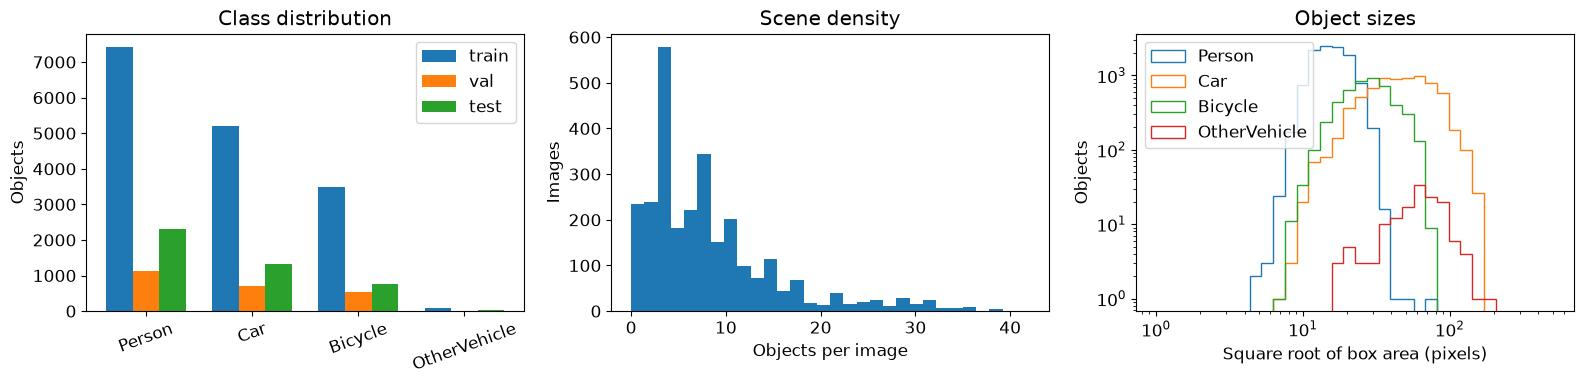

In [11]:
class_counts = {s: np.bincount(np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES))
                for s, recs in records.items()}
print(f'{"Class":<16}' + ''.join(f'{s:>10}' for s in records))
for i, name in enumerate(CLASSES):
    print(f'{name:<16}' + ''.join(f'{class_counts[s][i]:>10}' for s in records))
for split, recs in records.items():
    counts = np.array([len(r['labels']) for r in recs])
    print(f'{split}: objects/image mean={counts.mean():.2f}, median={np.median(counts):.0f}, '
          f'p95={np.percentile(counts, 95):.0f}, max={counts.max()}, empty={(counts == 0).sum()}')

all_recs = [r for recs in records.values() for r in recs]
box_sizes = np.concatenate([r['boxes'][:, 2:] - r['boxes'][:, :2] for r in all_recs])
box_labels = np.concatenate([r['labels'] for r in all_recs])
print('Median box width/height:', np.median(box_sizes, axis=0))
print(f'Boxes with area < 32² pixels: {(box_sizes.prod(axis=1) < 32**2).mean():.1%}')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = np.arange(len(CLASSES))
for i, split in enumerate(records):
    axes[0].bar(x + (i - 1) * 0.25, class_counts[split], width=0.25, label=split)
axes[0].set(xticks=x, xticklabels=CLASSES, ylabel='Objects', title='Class distribution')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend()
axes[1].hist([len(r['labels']) for r in all_recs], bins=30)
axes[1].set(xlabel='Objects per image', ylabel='Images', title='Scene density')
for i, name in enumerate(CLASSES):
    axes[2].hist(np.sqrt(box_sizes[box_labels == i].prod(axis=1)), bins=np.geomspace(1, 512, 35),
                 histtype='step', label=name)
axes[2].set(xscale='log', yscale='log', xlabel='Square root of box area (pixels)',
            ylabel='Objects', title='Object sizes')
axes[2].legend()
fig.tight_layout()
plt.show()

**Ответ:**

**Датасет.** Взял [HIT-UAV v1.2.1](https://zenodo.org/records/7633134), лицензия CC0 1.0. Это тепловизионные снимки с дрона размером 640×512, классы: Person, Car, Bicycle, OtherVehicle. Исходная разметка в JSON, нарезка изображений не нужна.

**Разделение данных.** Из исходных 2 898 изображений исключил 103 с DontCare, чтобы неопределённые объекты не считались фоном. Сохранил авторское разделение: осталось 1 954 / 285 / 556 изображений в train / val / test. Из-за фильтрации результат нельзя напрямую сравнивать с официальным бенчмарком; независимость сцен между сплитами отдельно не проверял.

**Что видно по статистике.** Объекты преимущественно мелкие: медианная рамка 21×24 пикселя, у 68,4% площадь меньше 32² пикселей. В среднем на снимке около 8 объектов, максимум 42. Есть сильный дисбаланс: Person 10 858, Car 7 236, Bicycle 4 785, OtherVehicle всего 142.

**Разметка.** Некорректных боксов не нашёл. Сохранил 32 изображения без объектов. Мелкие тепловые силуэты трудно различать, а прямоугольные рамки вокруг повёрнутых объектов захватывают фон.


## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes: np.ndarray, labels: np.ndarray, width: int, height: int) -> str:
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64)
    assert width > 0 and height > 0 and len(boxes) == len(labels)
    centers = (boxes[:, :2] + boxes[:, 2:]) / 2 / [width, height]
    sizes = (boxes[:, 2:] - boxes[:, :2]) / [width, height]
    return ''.join(f'{int(label)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n'
                   for label, (cx, cy), (w, h) in zip(labels, centers, sizes))


def from_yolo(text: str, width: int, height: int) -> tuple[np.ndarray, np.ndarray]:
    if not text.strip():
        return np.empty((0, 4), dtype=np.float32), np.empty(0, dtype=np.int64)
    rows = np.array([line.split() for line in text.splitlines() if line.strip()], dtype=np.float64)
    assert rows.shape[1] == 5 and width > 0 and height > 0
    centers = rows[:, 1:3] * [width, height]
    sizes = rows[:, 3:5] * [width, height]
    boxes = np.concatenate([centers - sizes / 2, centers + sizes / 2], axis=1)
    return boxes.astype(np.float32), rows[:, 0].astype(np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs: list[dict], split: str) -> None:
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    assert len({r['image'].stem for r in recs}) == len(recs)
    for record in recs:
        shutil.copy2(record['image'], image_dir / record['image'].name)
        text = to_yolo(record['boxes'], record['labels'], record['width'], record['height'])
        (label_dir / f"{record['image'].stem}.txt").write_text(text)


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {name}\n' for i, name in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'
print(DATA_YAML.read_text())

path: /Users/karpov0o0/MAIN/SELF/itmo/term-5/deep-learning/homeworks/hw-2/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: Person
  1: Car
  2: Bicycle
  3: OtherVehicle



Roundtrip: 2795 images, max coordinate error=0.000397 px


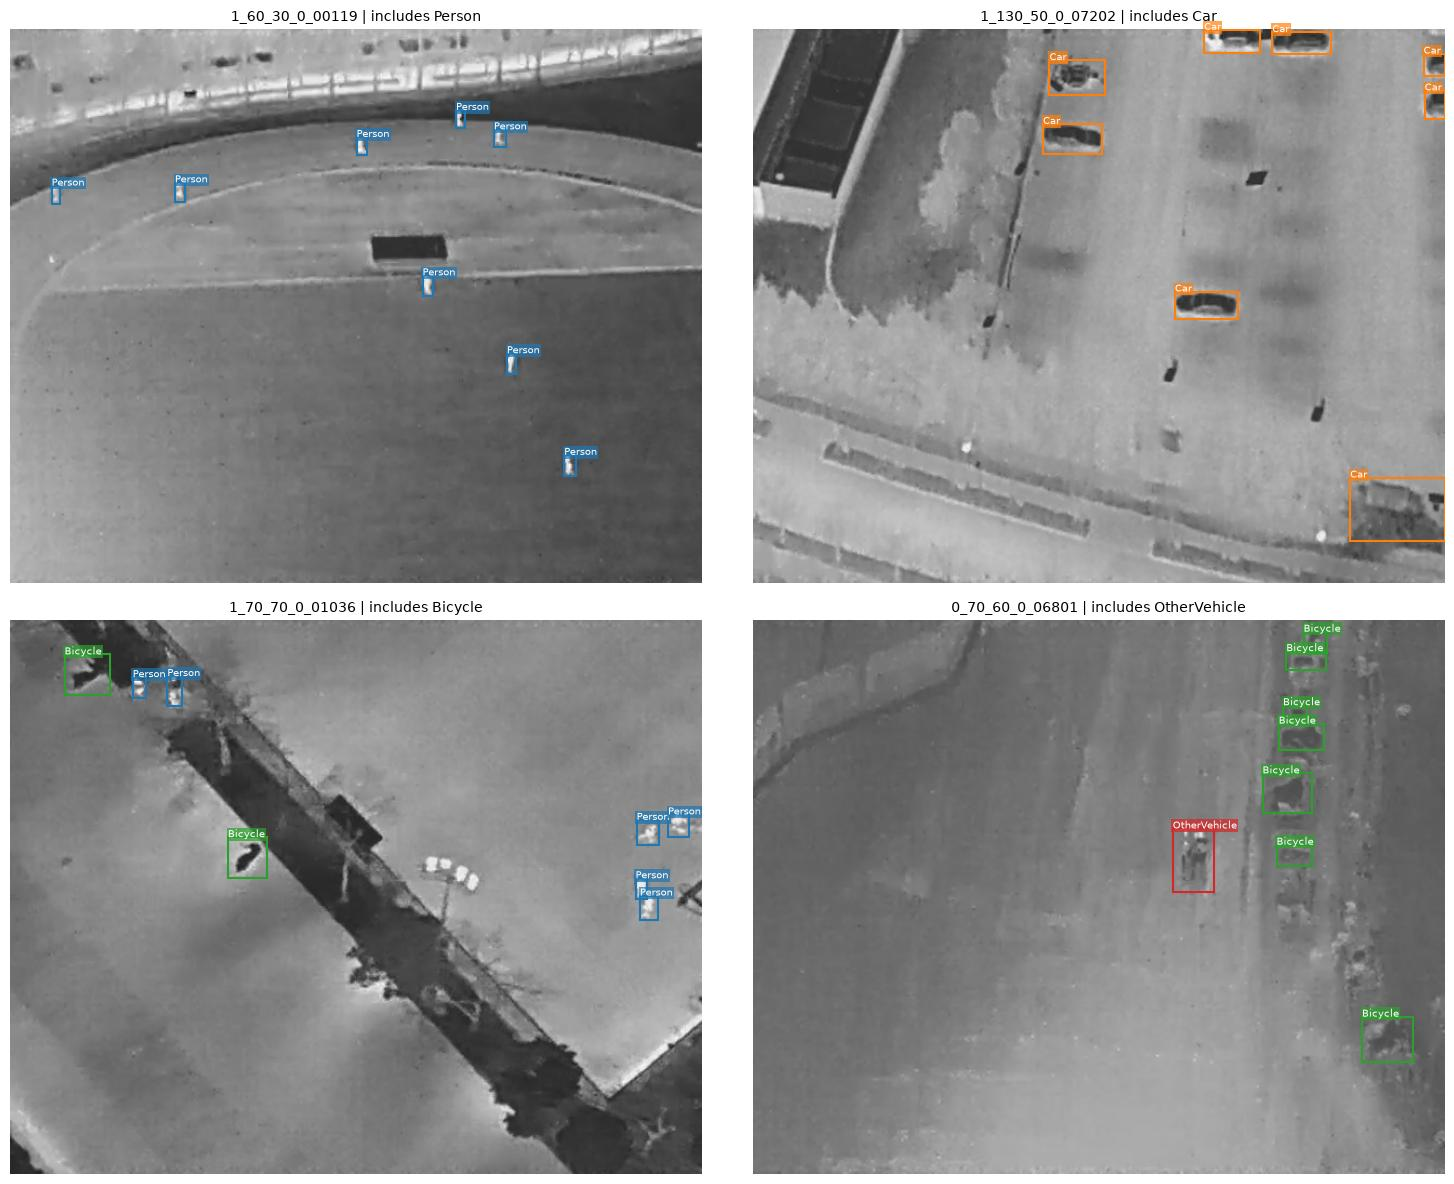

In [15]:
max_error = 0.0
for split, recs in splits.items():
    for record in recs:
        text = (YOLO_ROOT / 'labels' / split / f"{record['image'].stem}.txt").read_text()
        boxes, labels = from_yolo(text, record['width'], record['height'])
        assert np.array_equal(labels, record['labels'])
        assert boxes.shape == record['boxes'].shape
        error = float(np.max(np.abs(boxes - record['boxes']))) if len(boxes) else 0.0
        assert error < 0.001, (record['image'], error)
        max_error = max(max_error, error)
print(f'Roundtrip: {sum(map(len, splits.values()))} images, max coordinate error={max_error:.6f} px')

examples = []
for label in range(len(CLASSES)):
    candidates = [r for recs in splits.values() for r in recs if label in r['labels']
                  and r['image'] not in {e['image'] for e in examples}]
    examples.append(min(candidates, key=lambda r: abs(len(r['labels']) - 8)))
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, record, name in zip(axes.flat, examples, CLASSES):
    split = record['image'].parent.name
    text = (YOLO_ROOT / 'labels' / split / f"{record['image'].stem}.txt").read_text()
    boxes, labels = from_yolo(text, record['width'], record['height'])
    with Image.open(YOLO_ROOT / 'images' / split / record['image'].name) as image:
        draw_boxes(ax, image.convert('RGB'), boxes, labels, CLASSES,
                   title=f"{record['image'].stem} | includes {name}")
fig.tight_layout()
plt.show()

**Ответ:**

**Что проверил.** После конвертации в YOLO и обратно сохраняются классы и координаты рамок. Проверка прошла на всех 2 795 изображениях, максимальная ошибка координат меньше 0,001 пикселя.

**Ограничения.** Такой тест не проверяет исходную разметку и может пропустить взаимно обратные ошибки конвертеров. Поэтому посмотрел рамки на изображениях: так можно заметить смещение, перепутанные оси, неправильный масштаб или разметку от другой картинки.


---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [16]:
coco_to_hit = {0: 0, 2: 1, 1: 2}
start = time.perf_counter()
coco_preds = predict_records(model_coco, records[FINAL_SPLIT], batch=BATCH, rect=False)
for prediction in coco_preds:
    keep = np.isin(prediction['labels'], list(coco_to_hit))
    prediction['boxes'] = prediction['boxes'][keep]
    prediction['scores'] = prediction['scores'][keep]
    prediction['labels'] = np.array([coco_to_hit[int(c)] for c in prediction['labels'][keep]], dtype=np.int64)
coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['coco'] = time.perf_counter() - start
display(pd.DataFrame({'class': CLASSES, 'COCO AP50': coco_aps}))
print(f'COCO mAP50 ({FINAL_SPLIT}): {coco_map50:.4f}')

,class,COCO AP50
0,Person,0.081505
1,Car,0.295114
2,Bicycle,0.000000
3,OtherVehicle,0.000000


COCO mAP50 (test): 0.0942


In [17]:
def heuristic_detect(image_path: str | Path) -> dict[str, np.ndarray]:
    with Image.open(image_path) as image:
        width, height = image.size
    boxes, labels, scores = [], [], []
    centers = (np.arange(8) + 0.5) / 8
    for label, (box_width, box_height) in enumerate(mean_box_sizes):
        for cy in centers:
            for cx in centers:
                box = np.array([cx - box_width / 2, cy - box_height / 2,
                                cx + box_width / 2, cy + box_height / 2])
                boxes.append(np.clip(box, 0, 1) * [width, height, width, height])
                labels.append(label)
                scores.append(class_priors[label])
    return dict(boxes=np.asarray(boxes, dtype=np.float32),
                labels=np.asarray(labels, dtype=np.int64), scores=np.asarray(scores))

In [18]:
train_sizes = [[] for _ in CLASSES]
for record in records['train']:
    sizes = (record['boxes'][:, 2:] - record['boxes'][:, :2]) / [record['width'], record['height']]
    for size, label in zip(sizes, record['labels']):
        train_sizes[label].append(size)
mean_box_sizes = np.array([np.mean(sizes, axis=0) for sizes in train_sizes])
class_priors = np.array([len(sizes) for sizes in train_sizes], dtype=float)
class_priors /= class_priors.sum()
display(pd.DataFrame(mean_box_sizes, index=CLASSES, columns=['relative width', 'relative height']))

,relative width,relative height
Person,0.021272,0.039439
Car,0.082370,0.102886
Bicycle,0.047109,0.058052
OtherVehicle,0.096923,0.137516


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
display(pd.DataFrame({'class': CLASSES, 'COCO AP50': coco_aps, 'heuristic AP50': heuristic_aps}))
BASELINE

,class,COCO AP50,heuristic AP50
0,Person,0.081505,0.000004
1,Car,0.295114,0.000386
2,Bicycle,0.000000,0.000019
3,OtherVehicle,0.000000,0.000021


{'split': 'test',
 'coco_map50': 0.09415472493015062,
 'heuristic_map50': 0.00010766917698217524,
 'heuristic_ap50_per_class': {'Person': 4.143403255857227e-06,
  'Car': 0.00038579722399852465,
  'Bicycle': 1.939904861255409e-05,
  'OtherVehicle': 2.1337032061765016e-05}}

**Ответ:**

**Основной результат.** Без дообучения COCO-модель получила mAP50 = 0,0942 на test.

**Результат по классам.** AP50 у машин 0,2951, у людей 0,0815, у велосипедов 0. Для OtherVehicle прямого соответствия классу COCO нет, поэтому предсказания этого класса не формировались.

**Возможные причины.** Модель обучалась на обычных фотографиях, а здесь тепловизионная съёмка с дрона. Объекты выглядят иначе и занимают мало пикселей.

**Эвристика.** Средние рамки на сетке дали mAP50 = 0,000108. Она не использует содержимое изображения, поэтому почти не попадает в объекты ни одного класса.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(
    epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    optimizer='AdamW', lr0=0.001, lrf=0.01, weight_decay=0.0005,
    patience=15, seed=SEED, deterministic=True,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.2,
    fliplr=0.5, flipud=0.0, degrees=10.0, translate=0.1, scale=0.3,
    mosaic=0.5, close_mosaic=10 if not FAST_MODE else 0, mixup=0.0,
    val=True, plots=False,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

New https://pypi.org/project/ultralytics/8.4.212 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.208 🚀 Python-3.14.5 torch-2.14.1 MPS (Apple M4 Pro)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=10.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=15, perspective=0.0, plots=False, pose=12.0, pretr

Overriding model.yaml nc=80 with nc=4



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (7,810 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.8it/s 1.5s

                   all        285       2388       0.87       0.77      0.852      0.544


Speed: 0.1ms preprocess, 0.9ms inference, 0.0ms loss, 2.3ms postprocess per image


обучение: 4477 s на mps, каталог /Users/karpov0o0/MAIN/SELF/itmo/term-5/deep-learning/homeworks/hw-2/runs_hw2/finetune


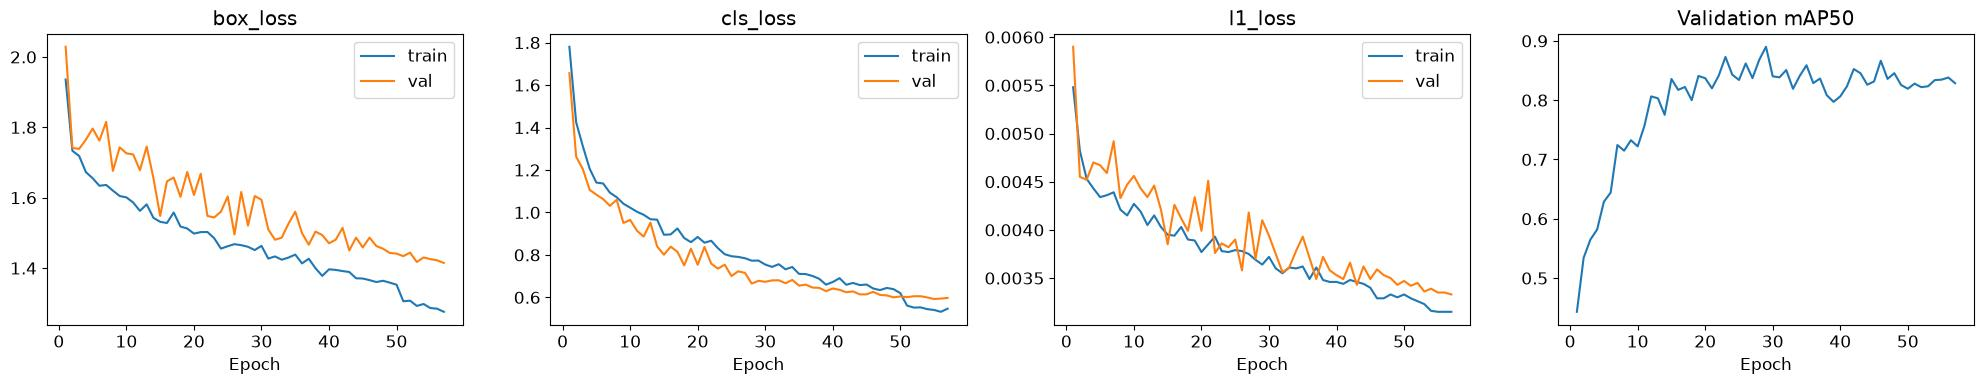

Epochs: 57, best val mAP50: 0.8900


In [22]:
history = read_results(run_dir)
loss_names = [key.removeprefix('train/') for key in history if key.startswith('train/') and key.endswith('loss')]
fig, axes = plt.subplots(1, len(loss_names) + 1, figsize=(5 * (len(loss_names) + 1), 4))
for ax, name in zip(axes, loss_names):
    for split in ('train', 'val'):
        key = f'{split}/{name}'
        if key in history:
            ax.plot(history['epoch'], history[key], label=split)
    ax.set(title=name, xlabel='Epoch')
    ax.legend()
axes[-1].plot(history['epoch'], history['metrics/mAP50(B)'])
axes[-1].set(title='Validation mAP50', xlabel='Epoch')
fig.tight_layout()
plt.show()
print(f'Epochs: {len(history["epoch"])}, best val mAP50: {history["metrics/mAP50(B)"].max():.4f}')

**Ответ:**

**Разрешение и batch.** Оставил 640, потому что это съёмка с дрона и объекты преимущественно мелкие: медианная рамка всего 21×24 пикселя. При уменьшении разрешения деталей станет ещё меньше. Batch = 16 помещается в память.

**Оптимизация.** Взял AdamW с lr = 0,001 как начальную настройку для дообучения готовых весов. Задал максимум 60 эпох и patience = 15, чтобы остановиться, если качество на val перестанет улучшаться.

**Аугментации.** Цветовой тон и насыщенность не менял, поскольку съёмка тепловизионная. Оставил изменение яркости, небольшие повороты, масштабирование и горизонтальное отражение. Вертикальное отражение отключил, так как часть кадров снята под наклоном. Mosaic с вероятностью 0,5 добавляет разнообразие сцен; на последних 10 запланированных эпохах он отключается.

**Результат обучения.** На Mac обучение заняло 74,6 минуты и остановилось после 57 эпох. Лучшие веса выбраны на 42-й по mAP50-95. Train и val loss в целом снижаются, явного переобучения по этим кривым не видно. Метрика вышла на плато: последние 15 эпох не улучшили лучший результат, поэтому для этого запуска эпох хватило.


## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.208 🚀 Python-3.14.5 torch-2.14.1 MPS (Apple M4 Pro)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2133.8±420.2 MB/s, size: 62.7 KB)


val: Scanning /Users/karpov0o0/MAIN/SELF/itmo/term-5/deep-learning/homeworks/hw-2/data/yolo/labels/val.cache... 285 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 285/285 239.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/18 1.4it/s 0.2s<12.1s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 11% ━─────────── 2/18 3.4it/s 0.3s<4.8s

... (58 outputs left out)

Speed: 0.1ms preprocess, 0.8ms inference, 0.0ms loss, 2.6ms postprocess per image


Results saved to /Users/karpov0o0/MAIN/SELF/itmo/term-5/deep-learning/homeworks/hw-2/runs_hw2/evaluate_test


precision  recall   map50  map50_95
split class_name                                       
val   all              0.8886  0.8100  0.8564    0.5322
      Person           0.9123  0.8492  0.9155    0.4839
      Car              0.9506  0.9373  0.9841    0.6822
      Bicycle          0.8637  0.7868  0.8639    0.4616
      OtherVehicle     0.8278  0.6667  0.6620    0.5010
test  all              0.8564  0.8180  0.8479    0.5349
      Person           0.8959  0.8662  0.9258    0.4888
      Car              0.9340  0.9382  0.9673    0.6771
      Bicycle          0.8693  0.8426  0.8941    0.5071
      OtherVehicle     0.7264  0.6250  0.6045    0.4665

mAP50: ultralytics=0.8479, evaluate_map50=0.8394, difference=-0.0085


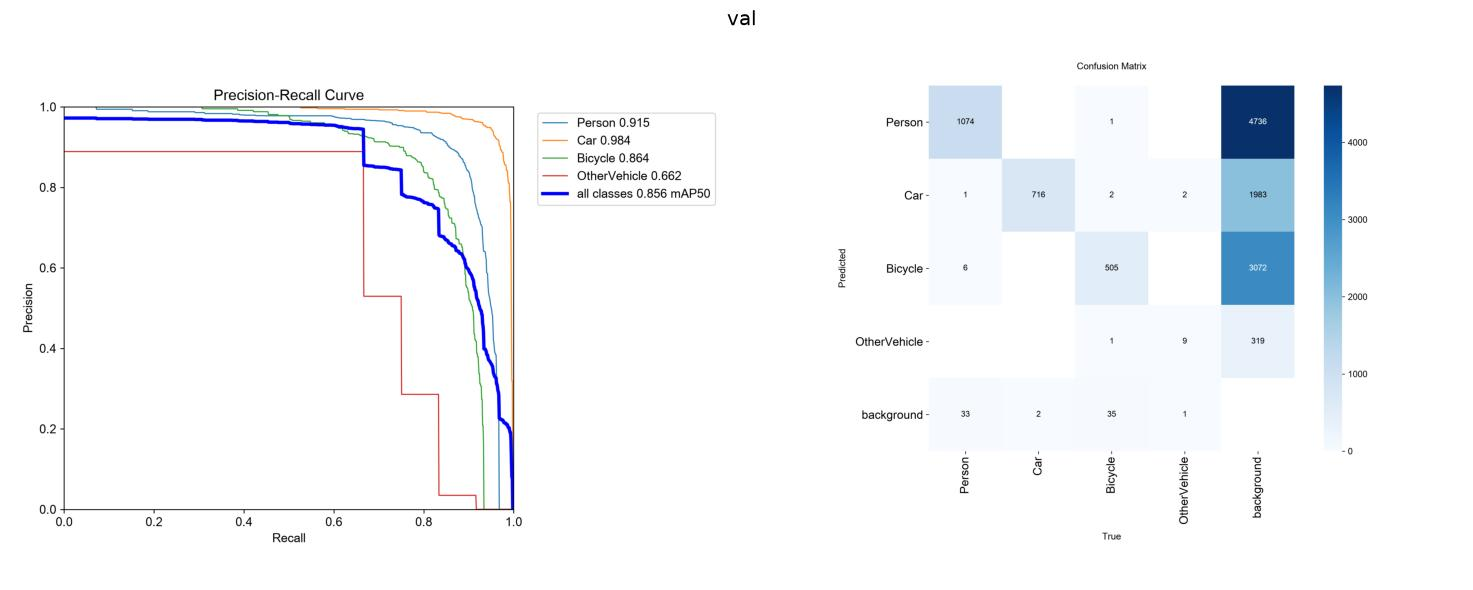

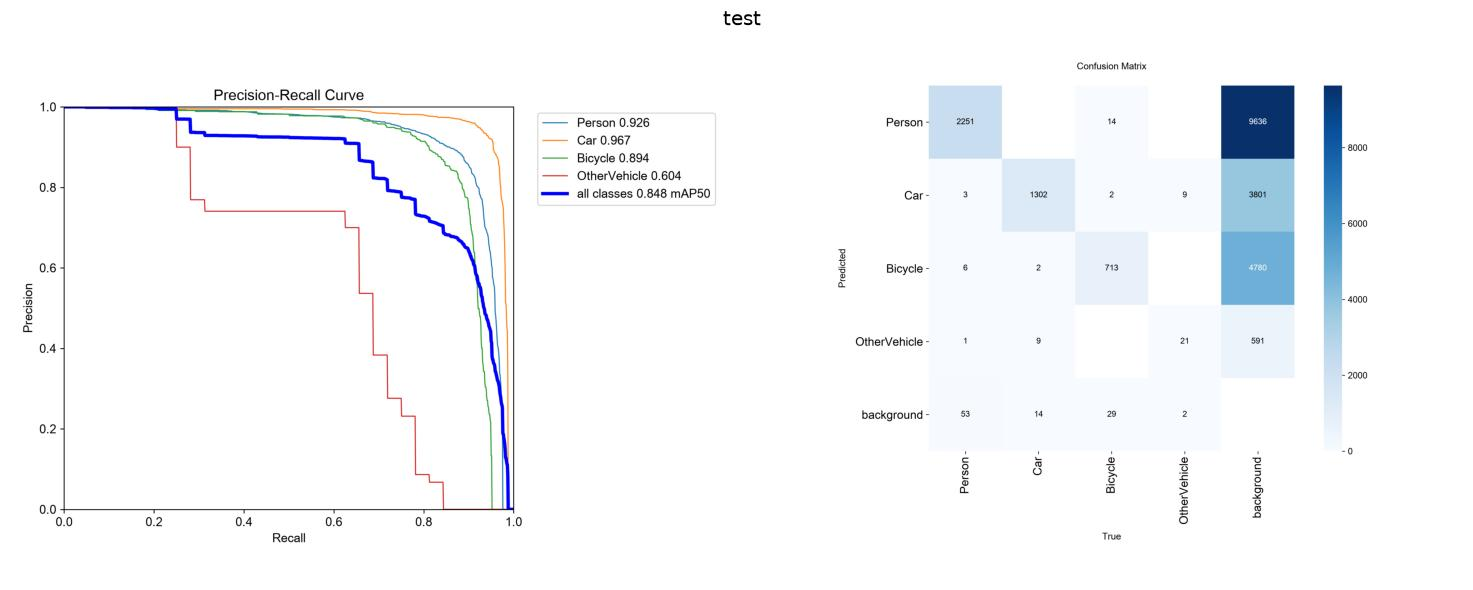

In [24]:
validation = {}
metric_rows = []
for split in ('val', 'test') if 'test' in records else ('val',):
    metrics = val_metrics(best, split, f'evaluate_{split}', plots=True, conf=0.001, rect=False)
    validation[split] = metrics
    metric_rows.append(dict(split=split, class_name='all', precision=metrics.box.mp,
                            recall=metrics.box.mr, map50=metrics.box.map50, map50_95=metrics.box.map))
    for i, label in enumerate(metrics.box.ap_class_index):
        precision, recall, map50, map50_95 = metrics.box.class_result(i)
        metric_rows.append(dict(split=split, class_name=CLASSES[label], precision=precision,
                                recall=recall, map50=map50, map50_95=map50_95))
display(pd.DataFrame(metric_rows).set_index(['split', 'class_name']).round(4))

metrics = validation[FINAL_SPLIT]
FINAL = dict(map50=float(metrics.box.map50), map50_95=float(metrics.box.map),
             precision=float(metrics.box.mp), recall=float(metrics.box.mr),
             per_class={row['class_name']: {key: float(row[key]) for key in ('precision', 'recall', 'map50', 'map50_95')}
                        for row in metric_rows if row['split'] == FINAL_SPLIT and row['class_name'] != 'all'})
final_preds = predict_records(best, records[FINAL_SPLIT], batch=BATCH, rect=False)
custom_map50, custom_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'mAP50: ultralytics={FINAL["map50"]:.4f}, evaluate_map50={custom_map50:.4f}, '
      f'difference={custom_map50 - FINAL["map50"]:+.4f}')

for split, metrics in validation.items():
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, filename in zip(axes, ('BoxPR_curve.png', 'confusion_matrix.png')):
        ax.imshow(plt.imread(Path(metrics.save_dir) / filename))
        ax.set_axis_off()
    fig.suptitle(split)
    fig.tight_layout()
    plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.8479, 'map50_95': 0.5349, 'precision': 0.8564, 'recall': 0.818}

**Ответ:**

**Основной результат.** На test получил mAP50 = 0,8479, mAP50-95 = 0,5349, precision = 0,8564 и recall = 0,8180.

**Результат по классам.** Лучше всего находятся машины, AP50 = 0,9673. Хуже всего OtherVehicle, AP50 = 0,6045: в train всего 98 таких объектов, а по матрице видно, что модель путает их с Car.

**Точность рамок.** mAP50-95 заметно ниже mAP50, потому что эта метрика требует более точного совпадения рамок. При съёмке с дрона объекты мелкие, поэтому даже сдвиг на несколько пикселей может сильно снизить IoU.

**Confusion matrix.** Строка background показывает пропуски, столбец background лишние предсказания. Здесь conf = 0,001, поэтому видно много низкоуверенных лишних рамок. Precision и recall в таблице рассчитаны при другом пороге, который максимизирует средний F1.

**Сверка mAP.** Функция из заготовки дала 0,8394 против 0,8479 у ultralytics. Расчёты отличаются интегрированием PR-кривой и сопоставлением рамок: библиотека ищет лучший свободный объект, а функция сначала выбирает максимальный IoU и затем проверяет, не занят ли объект.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [2]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    intersection = np.maximum(0, np.minimum(a[:, None, 2:], b[None, :, 2:])
                              - np.maximum(a[:, None, :2], b[None, :, :2])).prod(axis=2)
    area_a = np.maximum(0, a[:, 2:] - a[:, :2]).prod(axis=1)
    area_b = np.maximum(0, b[:, 2:] - b[:, :2]).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred: dict, gt: dict, iou_hit: float = 0.5,
                           iou_loc: float = 0.1) -> tuple[list[str], list[int]]:
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    found = np.zeros(len(gt['labels']), dtype=bool)
    explained = np.zeros_like(found)
    categories = ['background'] * len(pred['labels'])
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = np.asarray(gt['labels']) == pred['labels'][i]
        candidates = (
            ('tp', same & ~found & (ious[i] >= iou_hit)),
            ('class', ~same & (ious[i] >= iou_hit)),
            ('localization', same & ~found & (ious[i] >= iou_loc) & (ious[i] < iou_hit)),
        )
        for category, mask in candidates:
            indices = np.flatnonzero(mask)
            if len(indices):
                j = indices[np.argmax(ious[i, indices])]
                categories[i] = category
                explained[j] = True
                if category == 'tp':
                    found[j] = True
                break
    return categories, np.flatnonzero(~explained).tolist()


In [3]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


val: 285 images, 2388 objects, 2521 predictions, conf >= 0.25


,count,percent,denominator
tp,2168,86.00,predictions
class,10,0.40,predictions
localization,107,4.24,predictions
background,236,9.36,predictions
missed,132,5.53,GT objects


Prediction categories use the predicted class; missed uses the true class.


,tp,class,localization,background,missed
Person,1007,1,51,125,70
Car,693,5,5,45,20
Bicycle,460,1,51,66,39
OtherVehicle,8,3,0,0,3


Percent within each class; missed is divided by GT count.


,tp,class,localization,background,missed
Person,85.05,0.08,4.31,10.56,6.28
Car,92.65,0.67,0.67,6.02,2.79
Bicycle,79.58,0.17,8.82,11.42,7.17
OtherVehicle,72.73,27.27,0.00,0.00,25.00


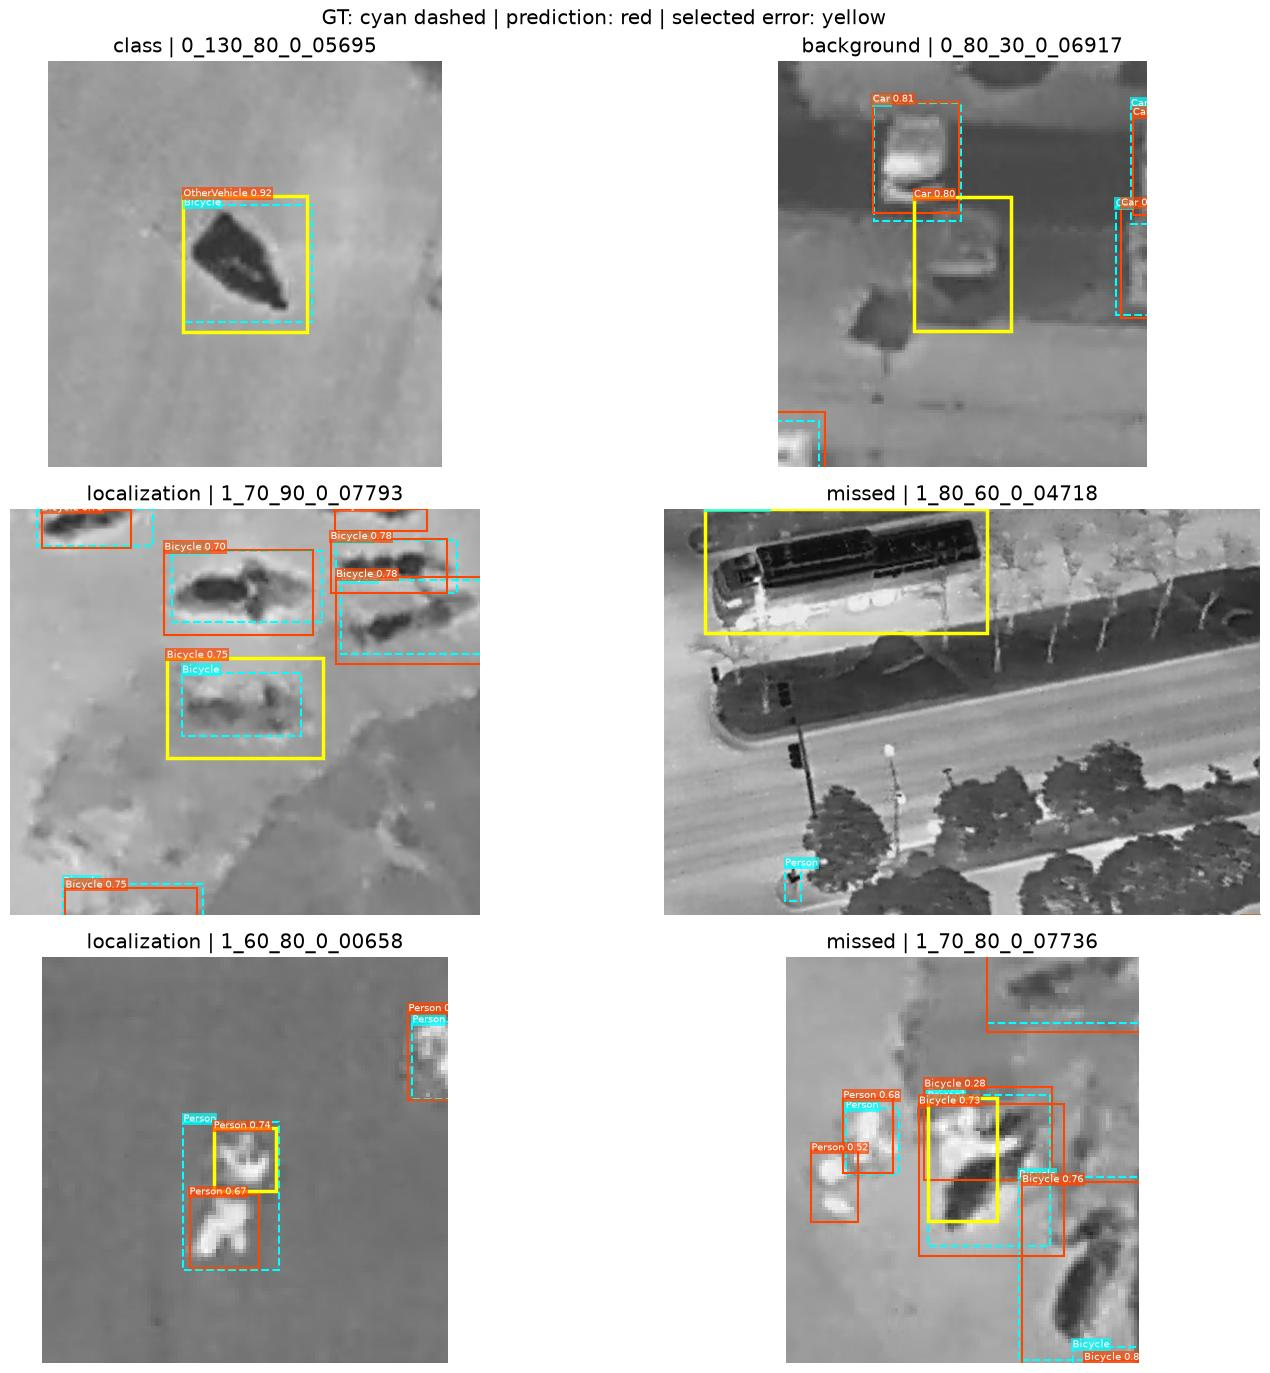

In [4]:
error_preds = predict_records(best, records['val'], conf=CONF_ERRORS, batch=BATCH, rect=False)
error_analysis = [categorize_predictions(pred, gt) for pred, gt in zip(error_preds, records['val'])]
ERRORS = dict.fromkeys(ERROR_TYPES, 0)
error_counts = pd.DataFrame(0, index=CLASSES, columns=ERROR_TYPES)
for pred, gt, (categories, missed) in zip(error_preds, records['val'], error_analysis):
    for label, category in zip(pred['labels'], categories):
        ERRORS[category] += 1
        error_counts.loc[CLASSES[label], category] += 1
    for j in missed:
        ERRORS['missed'] += 1
        error_counts.loc[CLASSES[gt['labels'][j]], 'missed'] += 1
n_predictions = sum(len(pred['labels']) for pred in error_preds)
n_objects = sum(len(gt['labels']) for gt in records['val'])
assert sum(ERRORS[c] for c in ERROR_TYPES[:-1]) == n_predictions
summary = pd.DataFrame({'count': ERRORS})
summary['percent'] = [100 * ERRORS[c] / max(1, n_objects if c == 'missed' else n_predictions)
                      for c in summary.index]
summary['denominator'] = ['GT objects' if c == 'missed' else 'predictions' for c in summary.index]
print(f'val: {len(records["val"])} images, {n_objects} objects, {n_predictions} predictions, conf >= {CONF_ERRORS}')
display(summary.round(2))
print('Prediction categories use the predicted class; missed uses the true class.')
display(error_counts)
gt_counts = np.bincount(np.concatenate([r['labels'] for r in records['val']]), minlength=len(CLASSES))
pred_counts = error_counts[list(ERROR_TYPES[:-1])].sum(axis=1)
error_rates = error_counts.astype(float)
error_rates[list(ERROR_TYPES[:-1])] = error_rates[list(ERROR_TYPES[:-1])].div(pred_counts.replace(0, np.nan), axis=0) * 100
error_rates['missed'] = 100 * error_counts['missed'] / gt_counts
print('Percent within each class; missed is divided by GT count.')
display(error_rates.round(2))

examples = []
used_images = set()
for category in ('class', 'background', 'localization', 'missed', 'localization', 'missed'):
    candidates = []
    for i, (pred, gt, (categories, missed)) in enumerate(zip(error_preds, records['val'], error_analysis)):
        if i in used_images:
            continue
        indices = missed if category == 'missed' else [j for j, value in enumerate(categories) if value == category]
        for j in indices:
            if category == 'missed' and any(c == 'missed' for c, _, _ in examples) and gt['labels'][j] != CLASSES.index('Person'):
                continue
            priority = float(np.prod(gt['boxes'][j, 2:] - gt['boxes'][j, :2])) if category == 'missed' else float(pred['scores'][j])
            candidates.append((priority, i, j))
    if candidates:
        _, i, j = max(candidates)
        examples.append((category, i, j))
        used_images.add(i)
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for ax in axes.flat:
    ax.set_axis_off()
for ax, (category, i, j) in zip(axes.flat, examples):
    gt, pred = records['val'][i], error_preds[i]
    target = gt['boxes'][j] if category == 'missed' else pred['boxes'][j]
    x1, y1, x2, y2 = target
    padding = max(45, float(max(x2 - x1, y2 - y1)))
    with Image.open(gt['image']) as image:
        draw_boxes(ax, image.convert('RGB'), gt['boxes'], gt['labels'], CLASSES,
                   color='cyan', linestyle='--')
    draw_boxes(ax, None, pred['boxes'], pred['labels'], CLASSES, scores=pred['scores'], color='orangered')
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='yellow', linewidth=2.5))
    ax.set_xlim(max(0, x1 - padding), min(gt['width'], x2 + padding))
    ax.set_ylim(min(gt['height'], y2 + padding), max(0, y1 - padding))
    for text in ax.texts:
        text.set_clip_on(True)
    ax.set_title(f"{category} | {gt['image'].stem}")
fig.suptitle('GT: cyan dashed | prediction: red | selected error: yellow')
fig.tight_layout()
plt.show()


**Ответ:**

**Основной результат.** При conf = 0,25 правильными оказались 2 168 из 2 521 предсказания, или 86%. Главная категория ошибок: лишние рамки, их 236 (9,36% предсказаний). Ошибок локализации 107 (4,24%), ошибок класса 10 (0,40%). Пропущено 132 из 2 388 объектов, или 5,53%; здесь доля считается от разметки, а не от предсказаний.

**Результат по классам.** Больше всего пропусков у людей: 70, у велосипедов 39. У OtherVehicle пропущено 3 объекта из 12, то есть 25%, но примеров этого класса в val слишком мало для устойчивого вывода.

**Что видно на примерах.** Не все ошибки однозначно связаны с моделью. Среди лишних рамок есть объект, похожий на машину, без рамки в разметке. В примере с человеком модель разбивает область одной GT-рамки на два предсказания; это тоже стоит проверить в разметке. При этом модель пропускает крупный автобус, поэтому объяснить все ошибки только маленьким размером объектов нельзя.

**Что бы изменил.** Сначала проверил бы спорную разметку, чтобы не пытаться исправлять правильные предсказания модели. Затем подобрал бы порог уверенности на val: повышение порога может убрать часть лишних рамок, но важно проверить, сколько объектов при этом начнёт пропускаться.


## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [2]:
ablation_args = {**TRAIN_ARGS, 'imgsz': 320}
_, RUN_TIMES['train_320'], run_dir_320 = train_yolo('finetune_320', **ablation_args)

ablation_rows = []
ablation_class_rows = []
for size, directory, elapsed in ((320, run_dir_320, RUN_TIMES['train_320']),
                                  (640, run_dir, RUN_TIMES['train'])):
    candidate = YOLO(directory / 'weights' / 'best.pt')
    result = candidate.val(data=str(DATA_YAML), split='val', imgsz=size, batch=BATCH,
                           device=DEVICE, workers=WORKERS, conf=0.001, rect=False, plots=False,
                           project=str(RUNS.resolve()), name=f'ablation_{size}', exist_ok=True, verbose=False)
    epochs_run = len(read_results(directory)['epoch'])
    ablation_rows.append(dict(imgsz=size, map50=float(result.box.map50),
                              map50_95=float(result.box.map), train_time_sec=elapsed, epochs=epochs_run))
    for i, label in enumerate(result.box.ap_class_index):
        ablation_class_rows.append(dict(imgsz=size, class_name=CLASSES[label],
                                        AP50=float(result.box.ap50[i]), AP50_95=float(result.box.ap[i])))
ABLATION = dict(parameter='imgsz', values=[320, 640], split='val', results=ablation_rows)
ablation_table = pd.DataFrame(ablation_rows).set_index('imgsz')
ablation_table['train_minutes'] = ablation_table['train_time_sec'] / 60
ablation_table['seconds_per_epoch'] = ablation_table['train_time_sec'] / ablation_table['epochs']
display(ablation_table.drop(columns='train_time_sec').round(4))
display(pd.DataFrame(ablation_class_rows).pivot(index='class_name', columns='imgsz', values=['AP50', 'AP50_95']).round(4))


Ultralytics 8.4.208 🚀 Python-3.14.5 torch-2.14.1 MPS (Apple M4 Pro)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 265.3±54.3 MB/s, size: 68.3 KB)


val: Scanning /Users/karpov0o0/MAIN/SELF/itmo/term-5/deep-learning/homeworks/hw-2/data/yolo/labels/val.cache... 285 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 285/285 298.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/18 1.3it/s 0.2s<12.7s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 16% ━━────────── 3/18 4.4it/s 0.4s<3.4s

... (32 outputs left out)

                   all        285       2388      0.889       0.81      0.856      0.532


Speed: 0.1ms preprocess, 0.8ms inference, 0.0ms loss, 3.4ms postprocess per image


,map50,map50_95,epochs,train_minutes,seconds_per_epoch
imgsz,,,,,
320,0.7870,0.4683,60,28.5023,28.5023
640,0.8564,0.5322,57,74.6167,78.5439


AP50         AP50_95        
imgsz            320     640     320     640
class_name                                  
Bicycle       0.7494  0.8639  0.3624  0.4616
Car           0.9651  0.9841  0.6570  0.6822
OtherVehicle  0.6045  0.6620  0.4704  0.5010
Person        0.8292  0.9155  0.3833  0.4839

**Ответ:**

**Что сравнил.** Обучение и оценку при разрешении 320 и 640. Остальные настройки оставил одинаковыми, для сравнения взял лучшие веса каждого прогона и один и тот же val.

**Качество.** При уменьшении разрешения mAP50 снизился с 0,8564 до 0,7870, mAP50-95 с 0,5322 до 0,4683. Сильнее всего снизился AP50 у велосипедов: с 0,8639 до 0,7494, и у людей: с 0,9155 до 0,8292. Это согласуется с потерей мелких деталей: при 320 медианная рамка занимает примерно 11×12 пикселей вместо 21×24.

**Время.** Прогон на 320 занял 28,5 минуты за 60 эпох, на 640 получилось 74,6 минуты за 57 эпох. Поскольку число эпох разное, сравнил и среднее время эпохи: 28,5 против 78,5 секунды. На 320 одна эпоха примерно в 2,76 раза быстрее.

**Выбор.** Для финальной модели оставил бы 640: на наших снимках выигрыш по времени сопровождается заметной потерей качества на людях и велосипедах. 320 использовал бы для быстрой проверки кода и настроек. Вывод основан на одном прогоне для каждого разрешения.


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**

Дообучение на HIT-UAV заметно помогло: mAP50 на test вырос примерно с 0,094 до 0,848, итоговый mAP50-95 составил 0,535. Эвристика со средними рамками почти не работала: mAP50 = 0,000108.

При разрешении 320 одна эпоха проходила в 2,76 раза быстрее, но mAP50 на val снизился с 0,856 до 0,787, особенно пострадали люди и велосипеды. Для финальной модели оставил бы 640, поскольку на снимках с дрона важно сохранять детали мелких объектов.

Чаще всего модель выдаёт лишние рамки: на val их 236, или 9,36% предсказаний, причём часть просмотренных случаев вызывает вопросы к разметке. Ограничения эксперимента: один seed, 285 изображений в val и всего 12 объектов OtherVehicle в нём. Дальше проверил бы спорную разметку и подобрал порог уверенности на val, чтобы уменьшить число лишних рамок без сильного роста пропусков.


### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [3]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [ ]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [ ]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

Ultralytics 8.4.208 🚀 Python-3.14.5 torch-2.14.1 MPS (Apple M4 Pro)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 198.6±57.5 MB/s, size: 74.1 KB)


val: Scanning /Users/karpov0o0/MAIN/SELF/itmo/term-5/deep-learning/homeworks/hw-2/data/yolo/labels/val.cache... 285 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 285/285 41.2Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/18 1.3s/it 0.4s<21.5s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 11% ━─────────── 2/18 3.2it/s 0.5s<5.0s

... (90 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 6.6it/s 2.7s

                   all        285       2388       0.43       0.33      0.294      0.129


Speed: 0.1ms preprocess, 0.7ms inference, 0.0ms loss, 2.7ms postprocess per image


,map50,map50_95,Person,Car,Bicycle,OtherVehicle
condition,,,,,,
clean,0.8564,0.5322,0.9155,0.9841,0.8639,0.6620
dark_0.5,0.7829,0.4778,0.8721,0.9589,0.8342,0.4666
noise_25,0.0020,0.0009,0.0029,0.0000,0.0050,0.0000
jpeg_5,0.2941,0.1291,0.4701,0.2022,0.4385,0.0656


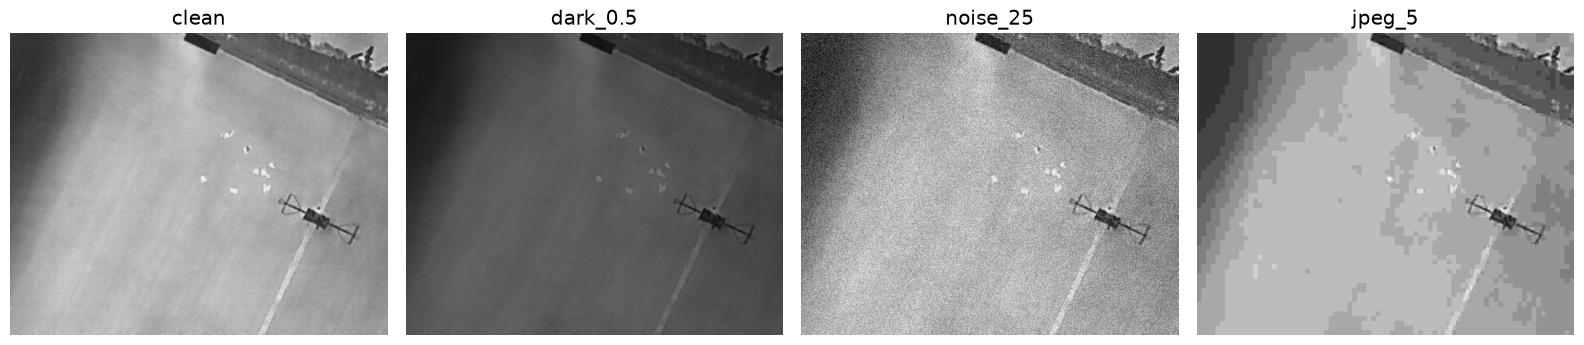

In [2]:
if '6.3' in BONUS_TASKS:
    from io import BytesIO

    def corrupt_image(image: Image.Image, kind: str, rng: np.random.Generator) -> Image.Image:
        pixels = np.asarray(image.convert('RGB'), dtype=np.float32)
        if kind == 'dark_0.5':
            pixels *= 0.5
        elif kind == 'noise_25':
            pixels += rng.normal(0, 25, (*pixels.shape[:2], 1))
        elif kind == 'jpeg_5':
            buffer = BytesIO()
            image.save(buffer, format='JPEG', quality=5)
            buffer.seek(0)
            return Image.open(buffer).convert('RGB')
        return Image.fromarray(np.clip(pixels, 0, 255).astype(np.uint8))

    corruption_rows = []
    for kind in ('clean', 'dark_0.5', 'noise_25', 'jpeg_5'):
        corruption_yaml = DATA_YAML
        if kind != 'clean':
            target = DATA_ROOT / 'hit_uav_corruptions' / kind
            (target / 'images/val').mkdir(parents=True, exist_ok=True)
            (target / 'labels/val').mkdir(parents=True, exist_ok=True)
            rng = np.random.default_rng(SEED)
            for record in records['val']:
                with Image.open(record['image']) as image:
                    changed = corrupt_image(image, kind, rng)
                    assert changed.size == (record['width'], record['height'])
                    changed.save(target / 'images/val' / f"{record['image'].stem}.png")
                shutil.copy2(YOLO_ROOT / 'labels/val' / f"{record['image'].stem}.txt", target / 'labels/val')
            corruption_yaml = target / 'data.yaml'
            corruption_yaml.write_text(json.dumps(dict(path=str(target.resolve()),
                train=str((YOLO_ROOT / 'images/train').resolve()), val='images/val', names=CLASSES)))
        measured = YOLO(run_dir / 'weights/best.pt').val(
            data=str(corruption_yaml), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
            workers=WORKERS, conf=0.001, rect=False, plots=False,
            project=str(RUNS.resolve()), name=f'corruption_{kind}', exist_ok=True, verbose=False)
        row = dict(condition=kind, map50=float(measured.box.map50), map50_95=float(measured.box.map))
        row.update({CLASSES[int(c)]: float(measured.box.ap50[i]) for i, c in enumerate(measured.box.ap_class_index)})
        corruption_rows.append(row)
    display(pd.DataFrame(corruption_rows).set_index('condition').round(4))
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    with Image.open(records['val'][0]['image']) as sample:
        for ax, kind in zip(axes, ('clean', 'dark_0.5', 'noise_25', 'jpeg_5')):
            ax.imshow(corrupt_image(sample, kind, np.random.default_rng(SEED)))
            ax.set_title(kind)
            ax.set_axis_off()
    fig.tight_layout()
    plt.show()
    BONUS_RESULTS['6.3'] = corruption_rows
    (artifact_dir / 'bonus_metrics.json').write_text(json.dumps(BONUS_RESULTS, ensure_ascii=False, indent=2))


**Ответ:**

**Что проверил.** Затемнение в 2 раза, гауссов шум со стандартным отклонением 25 на шкале 0–255 и JPEG с quality = 5. Изображения искажены, координаты разметки сохранены.

**Результат.** На исходном val mAP50 = 0,8564, после затемнения 0,7829, после JPEG 0,2941, после шума 0,0020. Из выбранных искажений сильнее всего повлиял шум: качество почти исчезло у всех классов. JPEG особенно ухудшил Car и OtherVehicle, а затемнение модель перенесла лучше.

**Что бы изменил.** Добавил бы шум и JPEG-сжатие в аугментации обучения, затем повторил проверку на тех же искажениях. Их пользу здесь ещё не проверял; вывод относится к выбранным уровням искажений.


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [4]:
if '6.4' in BONUS_TASKS:
    from typing import Callable
    from ultralytics.data.augment import LetterBox

    if any(importlib.util.find_spec(package) is None for package in ('onnx', 'onnxruntime')):
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'onnx', 'onnxruntime'], check=True)
    import onnxruntime as ort

    export_model = YOLO(run_dir / 'weights/best.pt')
    onnx_path = Path(export_model.export(format='onnx', imgsz=IMGSZ, batch=1, dynamic=False,
                                         simplify=False, nms=False, device='cpu'))
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.inter_op_num_threads = 1
    session = ort.InferenceSession(str(onnx_path), sess_options=options, providers=['CPUExecutionProvider'])
    reference = YOLO(run_dir / 'weights/best.pt').model.cpu().float().eval()
    reference.end2end = True
    reference.fuse(verbose=False)
    reference.model[-1].export = True
    reference.model[-1].format = 'onnx'
    inputs = []
    for record in records['val'][:10]:
        with Image.open(record['image']) as image:
            pixels = LetterBox((IMGSZ, IMGSZ), auto=False)(image=np.asarray(image.convert('RGB')))
        inputs.append(np.ascontiguousarray(pixels.transpose(2, 0, 1)[None], dtype=np.float32) / 255)
    input_name = session.get_inputs()[0].name
    torch_inputs = [torch.from_numpy(value) for value in inputs]

    def measure_forward(call: Callable[[int], object]) -> tuple[float, float]:
        for i in range(5):
            call(i % len(inputs))
        elapsed = []
        for i in range(30):
            started = time.perf_counter()
            call(i % len(inputs))
            elapsed.append(1000 * (time.perf_counter() - started))
        return float(np.mean(elapsed)), float(np.std(elapsed))

    previous_threads = torch.get_num_threads()
    torch.set_num_threads(1)
    try:
        with torch.inference_mode():
            native_output = reference(torch_inputs[0]).numpy()
            onnx_output = session.run(None, {input_name: inputs[0]})[0]
            assert native_output.shape == onnx_output.shape and np.isfinite(onnx_output).all()
            native_ms, native_std = measure_forward(lambda i: reference(torch_inputs[i]))
            onnx_ms, onnx_std = measure_forward(lambda i: session.run(None, {input_name: inputs[i]}))
    finally:
        torch.set_num_threads(previous_threads)
    speed_rows = []
    for name, path, latency, std in (('PyTorch', run_dir / 'weights/best.pt', native_ms, native_std),
                                     ('ONNX Runtime', onnx_path, onnx_ms, onnx_std)):
        measured = YOLO(path, task='detect').val(data=str(DATA_YAML), split='val', imgsz=IMGSZ,
            batch=1, device='cpu', workers=0, conf=0.001, rect=False, plots=False, nms=False,
            project=str(RUNS.resolve()), name=f'export_{name.split()[0].lower()}', exist_ok=True, verbose=False)
        speed_rows.append(dict(backend=name, latency_ms=latency, std_ms=std,
                               map50=float(measured.box.map50), map50_95=float(measured.box.map)))
    display(pd.DataFrame(speed_rows).set_index('backend').round(4))
    print(f'CPU, FP32, batch=1, one thread; model forward only; speed ratio={native_ms / onnx_ms:.2f}x')
    shutil.copy2(onnx_path, artifact_dir / 'best.onnx')
    BONUS_RESULTS['6.4'] = dict(device='cpu', threads=1, batch=1, precision='float32',
                               timing_scope='model forward', results=speed_rows)
    (artifact_dir / 'bonus_metrics.json').write_text(json.dumps(BONUS_RESULTS, ensure_ascii=False, indent=2))


Ultralytics 8.4.208 🚀 Python-3.14.5 torch-2.14.1 CPU (Apple M4 Pro)


YOLO26n summary (fused): 122 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs



PyTorch: starting from 'runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)



ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: export success ✅ 1.4s, saved as 'runs_hw2/finetune/weights/best.onnx' (9.4 MB)



Export complete (1.5s)
Results saved to /Users/karpov0o0/MAIN/SELF/itmo/term-5/deep-learning/homeworks/hw-2/runs_hw2/finetune/weights/best.onnx
Predict:         yolo predict task=detect model=runs_hw2/finetune/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=runs_hw2/finetune/weights/best.onnx imgsz=640 data=data/yolo/data.yaml 
Visualize:       https://netron.app


... (167 outputs left out)

                   all        285       2388      0.876      0.775      0.861      0.529


Speed: 0.9ms preprocess, 22.5ms inference, 0.0ms loss, 0.1ms postprocess per image


,latency_ms,std_ms,map50,map50_95
backend,,,,
PyTorch,66.1406,0.2391,0.861,0.5293
ONNX Runtime,28.1261,0.1718,0.861,0.5293


CPU, FP32, batch=1, one thread; model forward only; speed ratio=2.35x


**Ответ:**

**Условия сравнения.** Экспортировал лучшие веса в ONNX и сравнил с PyTorch: CPU, один поток, FP32, вход 640, batch = 1. Измерял только проход модели на заранее подготовленных изображениях, после 5 прогревочных запусков, по 30 замерам.

**Скорость и качество.** Средняя задержка снизилась с 66,14 до 28,13 мс, ускорение около 2,35 раза. mAP50 на val сохранился на уровне 0,8610, mAP50-95 на уровне 0,5293. В этих условиях потери качества от экспорта не обнаружил.

**Почему это работает.** ONNX Runtime выполняет модель как граф и применяет оптимизации его выполнения. Веса не дообучались и не квантизировались. Полученное ускорение относится к этому CPU и этим настройкам запуска.


## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [3]:
if '6.5' in BONUS_TASKS:
    threshold_rows = []
    for end2end in (True, False):
        for iou in (0.3, 0.7):
            detector = YOLO(run_dir / 'weights/best.pt')
            raw_predictions = predict_records(detector, records['val'], conf=0.001, batch=BATCH,
                                               rect=False, end2end=end2end, iou=iou)
            assert detector.predictor.model.end2end == end2end
            for conf in (0.001, 0.1, 0.25, 0.5):
                predictions = []
                for prediction in raw_predictions:
                    keep = prediction['scores'] >= conf
                    predictions.append({key: value[keep] for key, value in prediction.items()})
                true_positives = sum(categorize_predictions(pred, gt)[0].count('tp')
                                     for pred, gt in zip(predictions, records['val']))
                n_predictions = sum(len(pred['labels']) for pred in predictions)
                n_gt = sum(len(gt['labels']) for gt in records['val'])
                map50, _ = evaluate_map50(predictions, records['val'], len(CLASSES))
                threshold_rows.append(dict(mode='one2one' if end2end else 'one2many_NMS', conf=conf,
                    iou=iou, precision=true_positives / max(1, n_predictions), recall=true_positives / n_gt,
                    map50=map50, predictions=n_predictions))
    threshold_table = pd.DataFrame(threshold_rows)
    display(threshold_table.set_index(['mode', 'iou', 'conf']).round(4))
    e2e = threshold_table[threshold_table['mode'] == 'one2one'].drop(columns='mode').set_index(['conf', 'iou'])
    assert np.allclose(e2e.xs(0.3, level='iou'), e2e.xs(0.7, level='iou'))
    print('Precision/recall: fixed confidence threshold, IoU match >= 0.5; mAP50: evaluate_map50.')
    BONUS_RESULTS['6.5'] = threshold_rows
    (artifact_dir / 'bonus_metrics.json').write_text(json.dumps(BONUS_RESULTS, ensure_ascii=False, indent=2))


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


... (64 outputs left out)

WARNING ⚠️ 'end2end=False' is deprecated and will be removed in the future. Use 'nms=None' instead.


WARNING ⚠️ 'end2end=False' is deprecated and will be removed in the future. Use 'nms=None' instead.


precision  recall   map50  predictions
mode         iou conf                                         
one2one      0.3 0.001     0.1744  0.9770  0.8626        13381
                 0.100     0.7120  0.9288  0.8257         3115
                 0.250     0.8453  0.8832  0.7830         2495
                 0.500     0.9406  0.7563  0.6812         1920
             0.7 0.001     0.1744  0.9770  0.8626        13381
                 0.100     0.7120  0.9288  0.8257         3115
                 0.250     0.8453  0.8832  0.7830         2495
                 0.500     0.9406  0.7563  0.6812         1920
one2many_NMS 0.3 0.001     0.3746  0.9355  0.8451         5963
                 0.100     0.7979  0.9112  0.8104         2727
                 0.250     0.8704  0.8941  0.7987         2453
                 0.500     0.9415  0.8095  0.7413         2053
             0.7 0.001     0.2040  0.9678  0.8599        11331
                 0.100     0.6736  0.9393  0.8287         3330
                 0.250     0.8094  0.9158  0.8157         2702
                 0.500     0.9390  0.8187  0.7503         2082

Precision/recall: fixed confidence threshold, IoU match >= 0.5; mAP50: evaluate_map50.


**Ответ:**

**Порог уверенности.** При повышении conf модель оставляет меньше рамок: precision растёт, recall падает. Для one2one при conf = 0,25 получил precision = 0,8453 и recall = 0,8832; этот порог оставил бы как компромисс. При 0,5 precision уже 0,9406, но recall снижается до 0,7563.

**Порог NMS.** В one2one изменение iou с 0,3 до 0,7 не изменило результат, поскольку NMS в этом режиме не используется. В one2many с NMS меньший iou сильнее удаляет пересекающиеся рамки: при conf = 0,25 переход от 0,7 к 0,3 повысил precision с 0,8094 до 0,8704, но снизил recall с 0,9158 до 0,8941.

**Что происходит с mAP.** В этом эксперименте зависимость от conf заметная: у one2one mAP50 снизился с 0,8626 при 0,001 до 0,6812 при 0,5. AP учитывает PR-кривую, но заранее отброшенные предсказания в неё уже не попадают и ограничивают достижимый recall. Здесь P/R считаются по всем объектам при фиксированном пороге, mAP50 считается функцией из заготовки.
